In [6]:
!pip install drawdata

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 238.0/238.0 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 64.9 MB/s eta 0:00:00


In [7]:
from drawdata import ScatterWidget

ui = ScatterWidget()
ui

In [9]:
df = ui.data_as_pandas[["x","y","label"]]
df.head()

,x,y,label
0,607.115336,89.697827,a
1,666.770287,107.913638,a
2,637.209026,147.296331,a
3,633.594596,206.848210,a
4,594.176895,152.273191,a


In [10]:
df.label = df.label.map({"a":0,"b":1})
df.head()

,x,y,label
0,607.115336,89.697827,0
1,666.770287,107.913638,0
2,637.209026,147.296331,0
3,633.594596,206.848210,0
4,594.176895,152.273191,0


In [11]:
!pip install scikit-learn

In [13]:
from sklearn.model_selection import train_test_split

X = df[["x","y"]]
y = df.label

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)

## Model

In [1]:
import keras

In [4]:
model = keras.Sequential()
model.add(keras.Input(shape=(2,)))
model.add(keras.layers.Dense(3, activation="relu"))
model.add(keras.layers.Dense(2, activation="relu"))
model.add(keras.layers.Dense(1, activation="sigmoid"))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │             8 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20 (80.00 B)

 Trainable params: 20 (80.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    loss=keras.losses.BinaryCrossentropy(),
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    metrics=["accuracy"]
)

In [16]:
history = model.fit(X_train,y_train,epochs=100, validation_data=(X_test,y_test))

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.4865 - loss: 27.6382 - val_accuracy: 0.3158 - val_loss: 36.8335
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.4865 - loss: 27.1662 - val_accuracy: 0.3158 - val_loss: 36.1961
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4865 - loss: 26.6763 - val_accuracy: 0.3158 - val_loss: 35.5763
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.4865 - loss: 26.2145 - val_accuracy: 0.3158 - val_loss: 34.9618
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4865 - loss: 25.7708 - val_accuracy: 0.3158 - val_loss: 34.3536
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4865 - loss: 25.3178 - val_accuracy: 0.3158 - val_loss: 33.7558
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4865 - loss: 24.8538 - val_accuracy: 0.3158 - val_loss: 33.1616
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4865 - loss: 24.4207 - val_accuracy: 0.

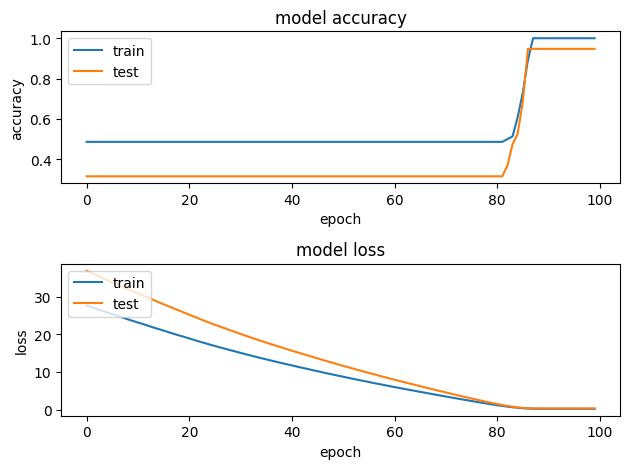

In [17]:
import matplotlib.pyplot as plt

plt.subplot(2,1,1)
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("model accuracy")
plt.ylabel("accuracy")
plt.xlabel("epoch")
plt.legend(["train", "test"], loc="upper left")

plt.subplot(2,1,2)
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("model loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train", "test"], loc="upper left")

plt.tight_layout()
plt.show()

In [18]:
model.evaluate(X_test,y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9474 - loss: 0.3150


[0.3149526119232178, 0.9473684430122375]

<Axes: xlabel='x', ylabel='y'>

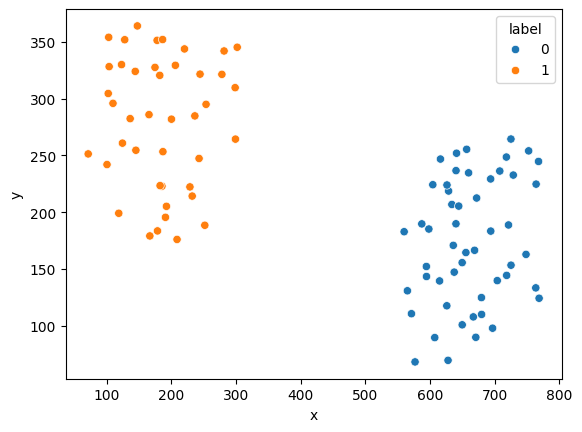

In [19]:
import seaborn as sns

sns.scatterplot(x="x",y="y",hue="label",data=df)

In [22]:
import numpy as np

In [35]:
model.predict(np.array([[800,220]]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step


array([[0.3487706]], dtype=float32)

In [26]:
model.predict(np.array([[20,100]]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


array([[1.]], dtype=float32)